In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

***Bu projede, çeşitli ikinci el araçların teknik özelliklerini ve satış verilerini içeren Kaggle "Vehicle Dataset" (Araç Veri Seti) kullanılmıştır.***

✪ **Veri setinin amacı:** Araçların model yılı, kilometresi, yakıt tipi, güncel sıfır fiyatı ve vites türü gibi bağımsız değişkenlerini kullanarak, o aracın "ikinci el satış fiyatını" en düşük hata payıyla tahmin edecek bir regresyon modeli geliştirmektir.

✪ **Veri setindeki değişkenler:** Veri setinde toplam 9 adet değişken (sütun) bulunmaktadır. Bunlar:

-*Car_Name:* Aracın markası ve modeli (Kategorik).

-*Year:* Aracın üretildiği/satın alındığı yıl (Sayısal).

-*Selling_Price:* Aracın ikinci el satış fiyatı (Sayısal - Hedef Değişken).

-*Present_Price:* Aracın güncel showroom (sıfır) fiyatı (Sayısal).

-*Kms_Driven:* Aracın kullanıldığı toplam kilometre (Sayısal).

-*Fuel_Type:* Aracın yakıt türü (Petrol, Diesel, CNG).

-*Seller_Type:* Satıcı türü (Dealer/Galeri, Individual/Bireysel).

-*Transmission:* Vites türü (Manual, Automatic).

-*Owner:* Aracın daha önceki sahip sayısı (Sayısal).

✪**Gözlem sayısı:** Veri setinde toplam 301 adet araca ait gözlem (satır) yer almaktadır.

✪**Hedef değişken:** Bu problemdeki hedef (bağımlı) değişkenimiz Selling_Price (İkinci El Satış Fiyatı) değişkenidir. Modelin asıl amacı bu değeri doğru tahmin etmektir.

In [2]:
# --- 1. Veri Setinin Yüklenmesi ---
df = pd.read_csv('used_cars.csv')

In [3]:
#İlk 5 Satır Görüntüleme
df.head()

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
#Sütunları İnceleme-Veri Tiplerini Gözlemleme
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [5]:
#Bazı İstatistiksel Değerler
df.describe()

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.644115,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


In [6]:
# --- 2. Veri Ön İşleme ---
# a. Araç adları modelde işe yaramayacağı için çıkarıyoruz
df = df.drop(['Car_Name'], axis=1)

In [7]:
# b. Araç yaşını hesaplayıp eski 'Year' sütununu çıkarıyoruz
df['Age'] = 2026 - df['Year']
df = df.drop('Year', axis=1)

In [8]:
# c. Eksik veri analizi
print("Eksik Veri Sayıları:\n", df.isnull().sum())

Eksik Veri Sayıları:
 Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
Age              0
dtype: int64


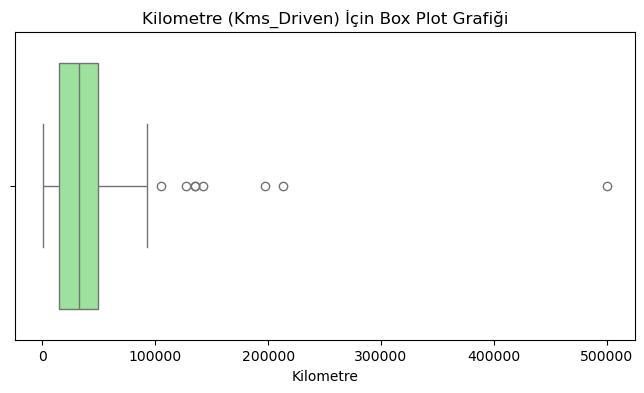

In [9]:
# Kilometre (Kms_Driven) değişkenindeki aykırı değerleri gösteren Box Plot Grafiği
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Kms_Driven'], color='lightgreen')
plt.title("Kilometre (Kms_Driven) İçin Box Plot Grafiği")
plt.xlabel("Kilometre")
plt.show()

In [10]:
# d. Aykırı değer analizi (Kms_Driven için IQR Yöntemi)
Q1 = df['Kms_Driven'].quantile(0.25)
Q3 = df['Kms_Driven'].quantile(0.75)
IQR = Q3 - Q1
ust_sinir = Q3 + 1.5 * IQR
df['Kms_Driven'] = np.where(df['Kms_Driven'] > ust_sinir, ust_sinir, df['Kms_Driven'])

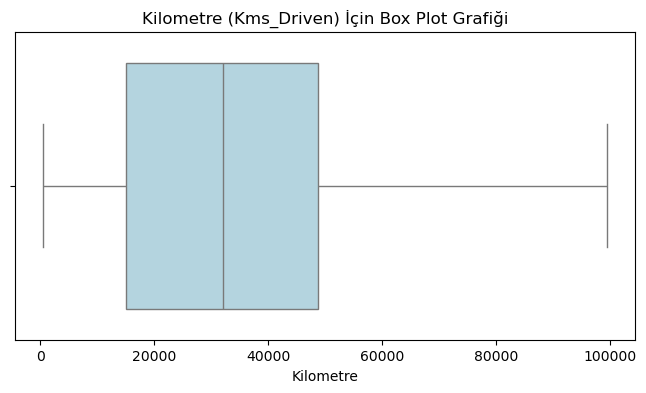

In [11]:
# Kilometre (Kms_Driven) değişkenine IQR Yöntemi Uygulandıktan Sonraki Hali
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Kms_Driven'], color='lightblue')
plt.title("Kilometre (Kms_Driven) İçin Box Plot Grafiği")
plt.xlabel("Kilometre")
plt.show()

In [12]:
# e. Kategorik Değişkenleri Sayısallaştırma (One-Hot Encoding)
# Fuel_Type, Seller_Type, Transmission sütunlarını 0 ve 1'lere dönüştürür
df = pd.get_dummies(df, drop_first=True)

In [13]:
df.head()

,Selling_Price,Present_Price,Kms_Driven,Owner,Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual
0,3.35,5.59,27000.0,0,12,False,True,False,True
1,4.75,9.54,43000.0,0,13,True,False,False,True
2,7.25,9.85,6900.0,0,9,False,True,False,True
3,2.85,4.15,5200.0,0,15,False,True,False,True
4,4.60,6.87,42450.0,0,12,True,False,False,True


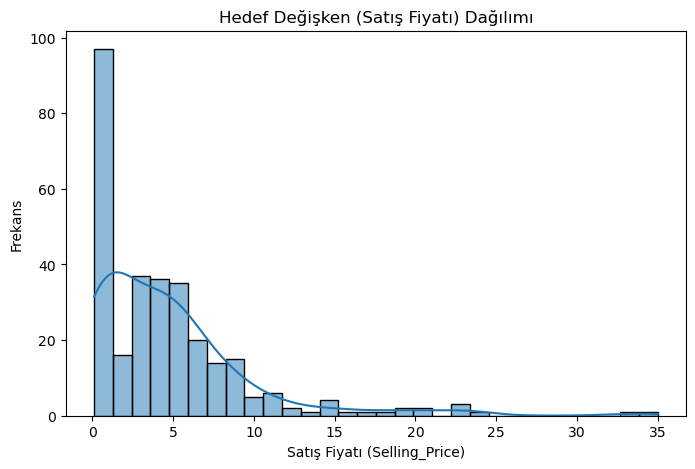

In [14]:
# --- 3. Veri Görselleştirme ---
plt.figure(figsize=(8, 5))
sns.histplot(df['Selling_Price'], bins=30, kde=True)
plt.title("Hedef Değişken (Satış Fiyatı) Dağılımı")
plt.xlabel("Satış Fiyatı (Selling_Price)")
plt.ylabel("Frekans")
plt.show()

In [15]:
# --- 4. Model Oluşturma ---
# Hedef değişken (y) ve bağımsız değişkenleri (X) ayırma
X = df.drop('Selling_Price', axis=1)
y = df['Selling_Price']

In [16]:
# Train-test split (%70 Eğitim, %30 Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

In [17]:
# Pipeline: Veri normalizasyonu (StandardScaler) ve Lineer Regresyon
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

In [18]:
# Modeli eğitme
pipeline.fit(X_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None


In [19]:
# Tahmin yapma
y_pred = pipeline.predict(X_test)

C:\Users\user\AppData\Local\Temp\ipykernel_15872\2436993940.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Etki_Katsayisi', y='Degisken', data=coef_df, palette='vlag')


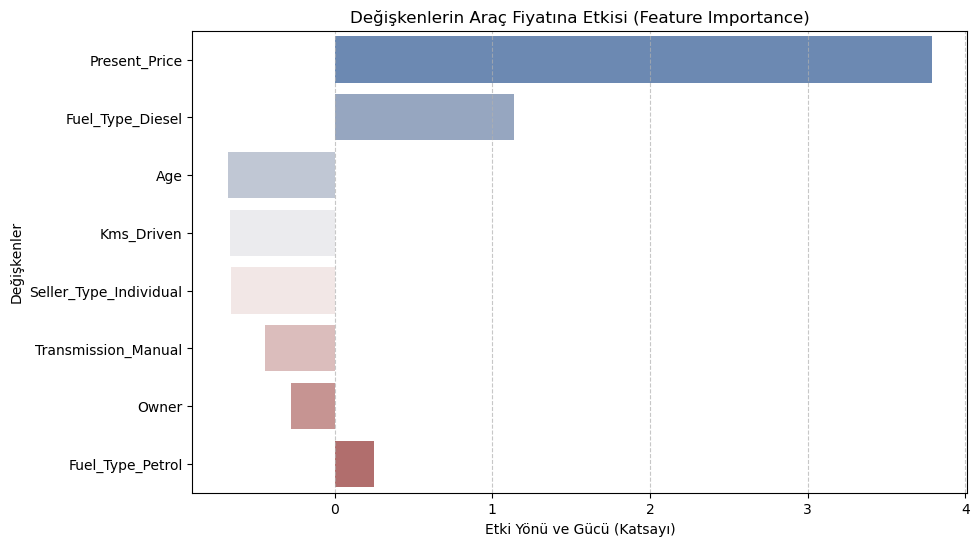

In [20]:
# --- Değişkenlerin Modele Olan Etkisini (Katsayıları) Görselleştirme ---
# Pipeline içinden eğitilmiş modelin katsayılarını çekiyoruz
katsayilar = pipeline.named_steps['model'].coef_
degiskenler = X_train.columns

# Katsayıları ve değişken isimlerini bir DataFrame'de birleştiriyoruz
coef_df = pd.DataFrame({
    'Degisken': degiskenler,
    'Etki_Katsayisi': katsayilar
})

# Etkinin büyüklüğünü görmek için mutlak değere göre sıralıyoruz
coef_df['Mutlak_Etki'] = coef_df['Etki_Katsayisi'].abs()
coef_df = coef_df.sort_values(by='Mutlak_Etki', ascending=False)

# Bar grafiğini çizdiriyoruz
plt.figure(figsize=(10, 6))
sns.barplot(x='Etki_Katsayisi', y='Degisken', data=coef_df, palette='vlag')
plt.title("Değişkenlerin Araç Fiyatına Etkisi (Feature Importance)")
plt.xlabel("Etki Yönü ve Gücü (Katsayı)")
plt.ylabel("Değişkenler")
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

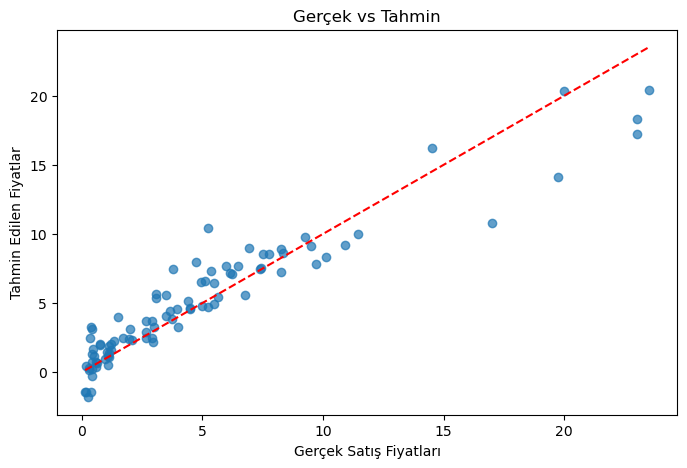

In [21]:
# --- Grafikler ---
# Grafik 1: Gerçek vs Tahmin
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Gerçek Satış Fiyatları")
plt.ylabel("Tahmin Edilen Fiyatlar")
plt.title("Gerçek vs Tahmin")
plt.show()

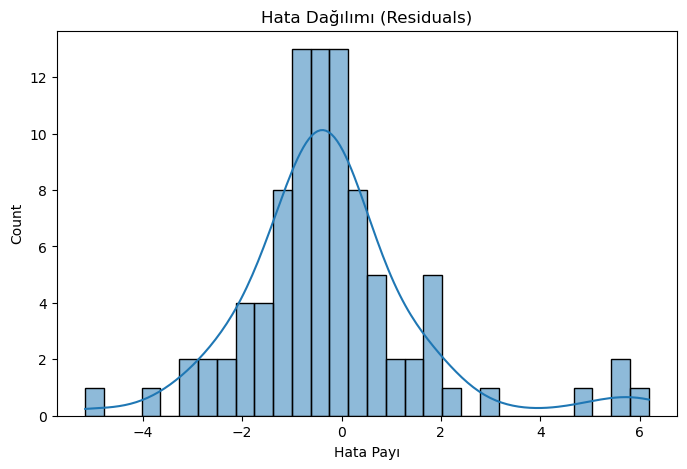

In [22]:
# Grafik 2: Hata Dağılımı (Residual Plot)
residuals = y_test - y_pred
plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=30, kde=True)
plt.title("Hata Dağılımı (Residuals)")
plt.xlabel("Hata Payı")
plt.show()

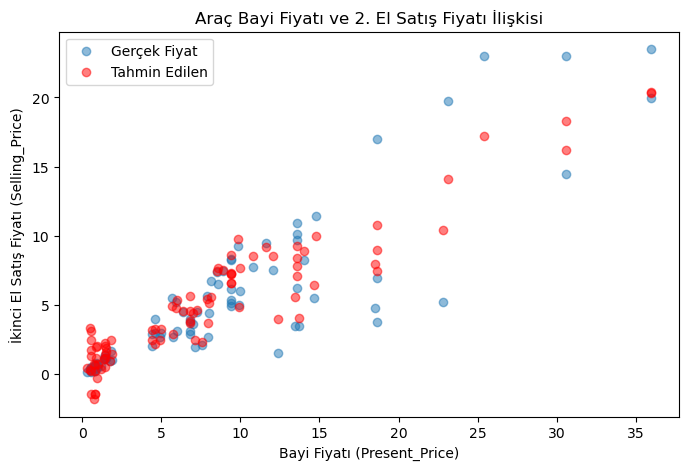

In [23]:
# Grafik 3: En önemli feature (Present_Price) ile hedef değişken ilişkisi
plt.figure(figsize=(8, 5))
plt.scatter(X_test['Present_Price'], y_test, alpha=0.5, label='Gerçek Fiyat')
plt.scatter(X_test['Present_Price'], y_pred, color='red', alpha=0.5, label='Tahmin Edilen')
plt.xlabel("Bayi Fiyatı (Present_Price)")
plt.ylabel("İkinci El Satış Fiyatı (Selling_Price)")
plt.title("Araç Bayi Fiyatı ve 2. El Satış Fiyatı İlişkisi")
plt.legend()
plt.show()

In [24]:
# --- 5. Model Değerlendirme Çıktıları---
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
train_pred = pipeline.predict(X_train)
train_r2 = r2_score(y_train, train_pred)

print("Model Değerlendirme Çıktıları")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"Test R²: {r2:.4f}")
print(f"Train R²: {train_r2:.4f}")

Model Değerlendirme Çıktıları
RMSE: 1.8074
MAE: 1.2320
Test R²: 0.8853
Train R²: 0.8895


****SONUÇLARIN YORUMLANMASI:****

➭**Model ne kadar başarılı?**

R² skorunun 0.8853 (%88) gibi oldukça yüksek bir seviyede çıkması, modelin araç fiyatlarındaki değişimi çok iyi açıkladığını ve bağımsız değişkenler arasındaki lineer ilişkiyi başarılı bir şekilde öğrendiğini göstermektedir.

➭**Hata değerleri ne anlama geliyor?** 

Modelin MAE değeri 1.23 olarak hesaplanmıştır. Bu, sistemin yaptığı fiyat tahminlerinin gerçek fiyattan ortalama 1.23 birimlik bir hata payına sahip olduğu anlamına gelmektedir ki modelin tutarlılığı göz önüne alındığında başarılı bir sonuçtur.